# Multimodal Skin Cancer Diagnosis (HAM10000)

Skin lesion image (CNN) + clinical data (age, sex, lesion location) fused to classify 7 lesion types.
The notebook trains two models and compares them: **image-only** vs **image + clinical (multimodal)**.

**How to run:** Google Colab -> Runtime -> Change runtime type -> **T4 GPU** -> Run all.
Each model takes roughly 20-30 minutes on a T4.

In [1]:
!pip-q install kagglehub

In [1]:
!ls /kaggle/input

datasets  notebooks


## 1. Setup

In [4]:
import os, glob, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import EfficientNetB0
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, recall_score, f1_score, accuracy_score

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 12

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("GPU available:", tf.config.list_physical_devices("GPU"))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load the dataset

Dataset: HAM10000 (about 10,000 dermatoscopic images with age, sex and lesion location).
If `kagglehub` asks for credentials, create a Kaggle API token (Kaggle -> Settings -> Create New Token) and follow the prompt.

In [5]:
import kagglehub

# If you downloaded and unzipped the dataset yourself, put that folder here and the download is skipped.
MANUAL_DATA_DIR = os.path.dirname(glob.glob("/kaggle/input/**/HAM10000_metadata.csv", recursive=True)[0])  # for example "/content/ham10000"

if MANUAL_DATA_DIR:
    DATA_DIR = MANUAL_DATA_DIR
else:
    try:
        DATA_DIR = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
    except Exception as err:
        print("Download failed:", err)
        print("Starting kagglehub.login(): enter your Kaggle username and API token when asked.")
        kagglehub.login()
        DATA_DIR = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Dataset folder:", DATA_DIR)

meta = pd.read_csv(os.path.join(DATA_DIR, "HAM10000_metadata.csv"))

image_paths = {}
for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True):
    image_paths[os.path.splitext(os.path.basename(p))[0]] = p

meta["path"] = meta["image_id"].map(image_paths)
print("Images without a file:", meta["path"].isna().sum())
meta = meta.dropna(subset=["path"]).reset_index(drop=True)

print(meta.shape)
meta.head()

Dataset folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Images without a file: 0
(10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/kmader/skin-cancer-mnis...


In [6]:
print(meta["dx"].value_counts())
print()
print(meta[["age"]].isna().sum())
print(meta["sex"].value_counts())
print(meta["localization"].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

age    57
dtype: int64
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64


## 3. Labels and train / validation / test split

HAM10000 contains several images of the same lesion (same `lesion_id`).
If those images land in both train and test, the model is tested on lesions it has effectively seen, and the score looks better than it is (data leakage).
So the split is done **by lesion_id**, not by image.

In [11]:
classes = sorted(meta["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
meta["label"] = meta["dx"].map(class_to_idx)
print(class_to_idx)

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss.split(meta, groups=meta["lesion_id"]))
train_df = meta.iloc[train_idx].reset_index(drop=True)
temp_df = meta.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["lesion_id"]))
val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

print(len(train_df), len(val_df), len(test_df))
assert set(train_df["lesion_id"]).isdisjoint(test_df["lesion_id"])
assert set(train_df["lesion_id"]).isdisjoint(val_df["lesion_id"])

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
7002 1519 1494


## 4. Clinical data preprocessing

Everything is fitted on the **training set only**, then applied to validation and test, so no information leaks from them.
- Missing age -> filled with the training median
- Age -> standardized
- Sex and lesion location -> one-hot encoded

In [12]:
age_median = train_df["age"].median()
for d in (train_df, val_df, test_df):
    d["age"] = d["age"].fillna(age_median)
    d["sex"] = d["sex"].fillna("unknown")

cat_cols = ["sex", "localization"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
scaler = StandardScaler()
encoder.fit(train_df[cat_cols])
scaler.fit(train_df[["age"]])

def clinical_features(d):
    age = scaler.transform(d[["age"]])
    cat = encoder.transform(d[cat_cols])
    return np.hstack([age, cat]).astype("float32")

Xc_train = clinical_features(train_df)
Xc_val = clinical_features(val_df)
Xc_test = clinical_features(test_df)
CLINICAL_DIM = Xc_train.shape[1]
print("Clinical feature size:", CLINICAL_DIM)

Clinical feature size: 19


## 5. Input pipeline

In [13]:
def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img  # EfficientNet expects raw 0-255 pixels

def make_dataset(df, clinical, use_clinical, training):
    paths = df["path"].values
    labels = df["label"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, clinical, labels))
    if training:
        ds = ds.shuffle(len(df), seed=SEED)

    def _map(path, clin, y):
        inputs = {"image": load_image(path)}
        if use_clinical:
            inputs["clinical"] = clin
        return inputs, y

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

weights = compute_class_weight("balanced", classes=np.arange(len(classes)), y=train_df["label"].values)
class_weight = dict(enumerate(weights))
print({classes[k]: round(v, 2) for k, v in class_weight.items()})

{'akiec': np.float64(4.83), 'bcc': np.float64(2.63), 'bkl': np.float64(1.35), 'df': np.float64(11.24), 'mel': np.float64(1.3), 'nv': np.float64(0.21), 'vasc': np.float64(10.42)}


## 6. Model

- **Image branch:** EfficientNetB0 (ImageNet pretrained) with light augmentation
- **Clinical branch:** small dense network on age, sex and location
- **Fusion:** concatenate both feature vectors, then a dense classifier (7 classes)

Training is in two phases: first only the new layers (backbone frozen), then fine-tune the top of the backbone with a very small learning rate.

In [27]:
def build_model(use_clinical):
    img_in = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = layers.RandomFlip("horizontal_and_vertical")(img_in)
    x = layers.RandomRotation(0.15)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.1)(x)

    backbone = EfficientNetB0(include_top=False, weights="imagenet",
                              input_shape=(IMG_SIZE, IMG_SIZE, 3))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    if use_clinical:
        clin_in = layers.Input(shape=(CLINICAL_DIM,), name="clinical")
        c = layers.Dense(64, activation="relu")(clin_in)
        c = layers.BatchNormalization()(c)
        c = layers.Dropout(0.2)(c)
        c = layers.Dense(32, activation="relu")(c)
        x = layers.Concatenate()([x, c])
        inputs = {"image": img_in, "clinical": clin_in}
    else:
        inputs = {"image": img_in}

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(classes), activation="softmax")(x)
    return models.Model(inputs, out)


def train(model, train_ds, val_ds, name):
    cbs = [
        callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_loss", save_best_only=True),
        callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    ]

    # Phase 1: train the new layers only
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              class_weight=class_weight, callbacks=cbs)

    # Phase 2: fine-tune the top of the backbone (BatchNorm layers stay frozen)
    backbone = next(l for l in model.layers if isinstance(l, tf.keras.Model))
    backbone.trainable = True
    for layer in backbone.layers[:-40]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
              class_weight=class_weight, callbacks=cbs)
    return model

## 7. Train model A: image only

In [28]:
train_img = make_dataset(train_df, Xc_train, use_clinical=False, training=True)
val_img = make_dataset(val_df, Xc_val, use_clinical=False, training=False)
test_img = make_dataset(test_df, Xc_test, use_clinical=False, training=False)

model_img = build_model(use_clinical=False)
model_img = train(model_img, train_img, val_img, name="image_only")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8


E0000 00:00:1795774125.070570      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 51s 161ms/step - accuracy: 0.4007 - loss: 1.6138 - val_accuracy: 0.5102 - val_loss: 1.2732 - learning_rate: 0.0010
Epoch 2/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.4880 - loss: 1.3226 - val_accuracy: 0.5721 - val_loss: 1.0875 - learning_rate: 0.0010
Epoch 3/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.5251 - loss: 1.2188 - val_accuracy: 0.6122 - val_loss: 1.0374 - learning_rate: 0.0010
Epoch 4/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 97ms/step - accuracy: 0.5336 - loss: 1.1939 - val_accuracy: 0.6438 - val_loss: 0.9819 - learning_rate: 0.0010
Epoch 5/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 98ms/step - accuracy: 0.5388 - loss: 1.1264 - val_accuracy: 0.6175 - val_loss: 0.9765 - learning_rate: 0.0010
Epoch 6/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.5380 - loss: 1.1106 - val_accuracy: 0.5951 - val_loss: 1.0048 - learning_rate: 0.0010
Epoch 7/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 95ms/step - accuracy: 0.5600 - loss: 1.0510 - va

E0000 00:00:1795774324.972804      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 37s 119ms/step - accuracy: 0.5691 - loss: 1.0414 - val_accuracy: 0.6366 - val_loss: 0.9283 - learning_rate: 1.0000e-05
Epoch 2/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - accuracy: 0.5844 - loss: 0.9854 - val_accuracy: 0.6425 - val_loss: 0.9008 - learning_rate: 1.0000e-05
Epoch 3/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - accuracy: 0.5867 - loss: 0.9745 - val_accuracy: 0.6438 - val_loss: 0.8916 - learning_rate: 1.0000e-05
Epoch 4/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 104ms/step - accuracy: 0.6075 - loss: 0.9332 - val_accuracy: 0.6333 - val_loss: 0.9175 - learning_rate: 1.0000e-05
Epoch 5/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 104ms/step - accuracy: 0.6097 - loss: 0.9112 - val_accuracy: 0.6307 - val_loss: 0.9028 - learning_rate: 1.0000e-05
Epoch 6/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - accuracy: 0.6083 - loss: 0.8923 - val_accuracy: 0.6399 - val_loss: 0.8806 - learning_rate: 5.0000e-06
Epoch 7/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 108ms/step - 

## 8. Train model B: image + clinical (multimodal)

In [29]:
train_mm = make_dataset(train_df, Xc_train, use_clinical=True, training=True)
val_mm = make_dataset(val_df, Xc_val, use_clinical=True, training=False)
test_mm = make_dataset(test_df, Xc_test, use_clinical=True, training=False)

model_mm = build_model(use_clinical=True)
model_mm = train(model_mm, train_mm, val_mm, name="multimodal")

Epoch 1/8


E0000 00:00:1795774631.169778      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 35s 114ms/step - accuracy: 0.4323 - loss: 1.5601 - val_accuracy: 0.6024 - val_loss: 1.1673 - learning_rate: 0.0010
Epoch 2/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 98ms/step - accuracy: 0.5297 - loss: 1.1943 - val_accuracy: 0.5339 - val_loss: 1.2060 - learning_rate: 0.0010
Epoch 3/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 102ms/step - accuracy: 0.5723 - loss: 1.0751 - val_accuracy: 0.6722 - val_loss: 0.9054 - learning_rate: 0.0010
Epoch 4/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.5904 - loss: 1.0209 - val_accuracy: 0.6689 - val_loss: 0.9220 - learning_rate: 0.0010
Epoch 5/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 100ms/step - accuracy: 0.5864 - loss: 0.9980 - val_accuracy: 0.6972 - val_loss: 0.8279 - learning_rate: 0.0010
Epoch 6/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 97ms/step - accuracy: 0.6207 - loss: 0.8977 - val_accuracy: 0.6452 - val_loss: 0.9390 - learning_rate: 0.0010
Epoch 7/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.6304 - loss: 0.9013 - 

E0000 00:00:1795774818.709083      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 37s 119ms/step - accuracy: 0.6341 - loss: 0.8965 - val_accuracy: 0.6893 - val_loss: 0.8561 - learning_rate: 1.0000e-05
Epoch 2/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 111ms/step - accuracy: 0.6505 - loss: 0.8037 - val_accuracy: 0.6899 - val_loss: 0.8223 - learning_rate: 1.0000e-05
Epoch 3/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - accuracy: 0.6571 - loss: 0.8315 - val_accuracy: 0.6794 - val_loss: 0.8386 - learning_rate: 1.0000e-05
Epoch 4/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - accuracy: 0.6622 - loss: 0.8078 - val_accuracy: 0.6919 - val_loss: 0.8083 - learning_rate: 1.0000e-05
Epoch 5/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - accuracy: 0.6687 - loss: 0.7771 - val_accuracy: 0.6893 - val_loss: 0.8156 - learning_rate: 1.0000e-05
Epoch 6/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - accuracy: 0.6769 - loss: 0.7628 - val_accuracy: 0.6972 - val_loss: 0.7924 - learning_rate: 1.0000e-05
Epoch 7/12
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 106ms/step - 

## 9. Evaluation on the held-out test set

Accuracy alone is misleading here because the classes are heavily imbalanced (the `nv` class dominates).
The main metric is **macro recall** (every class counts equally, and missing a cancer is the costly error), with macro F1 and **melanoma recall** alongside.

In [30]:
y_true = test_df["label"].values
mel_idx = class_to_idx["mel"]

def evaluate(model, ds, name):
    probs = model.predict(ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=classes, digits=3, zero_division=0))
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "melanoma_recall": recall_score(y_true, y_pred, labels=[mel_idx], average=None, zero_division=0)[0],
    }, y_pred

res_img, pred_img = evaluate(model_img, test_img, "Image only")
res_mm, pred_mm = evaluate(model_mm, test_mm, "Image + clinical")

results = pd.DataFrame([res_img, res_mm]).set_index("model").round(3)
results.to_csv("results.csv")
results

===== Image only =====
              precision    recall  f1-score   support

       akiec      0.529     0.571     0.550        63
         bcc      0.556     0.515     0.534        68
         bkl      0.424     0.566     0.485       152
          df      0.150     0.857     0.255         7
         mel      0.309     0.599     0.407       187
          nv      0.950     0.685     0.796       996
        vasc      0.513     0.952     0.667        21

    accuracy                          0.654      1494
   macro avg      0.490     0.678     0.528      1494
weighted avg      0.770     0.654     0.689      1494

===== Image + clinical =====
              precision    recall  f1-score   support

       akiec      0.500     0.444     0.471        63
         bcc      0.543     0.559     0.551        68
         bkl      0.462     0.671     0.547       152
          df      0.304     1.000     0.467         7
         mel      0.327     0.567     0.415       187
          nv      0.956   

,accuracy,macro_recall,macro_f1,melanoma_recall
model,,,,
Image only,0.654,0.678,0.528,0.599
Image + clinical,0.691,0.704,0.571,0.567


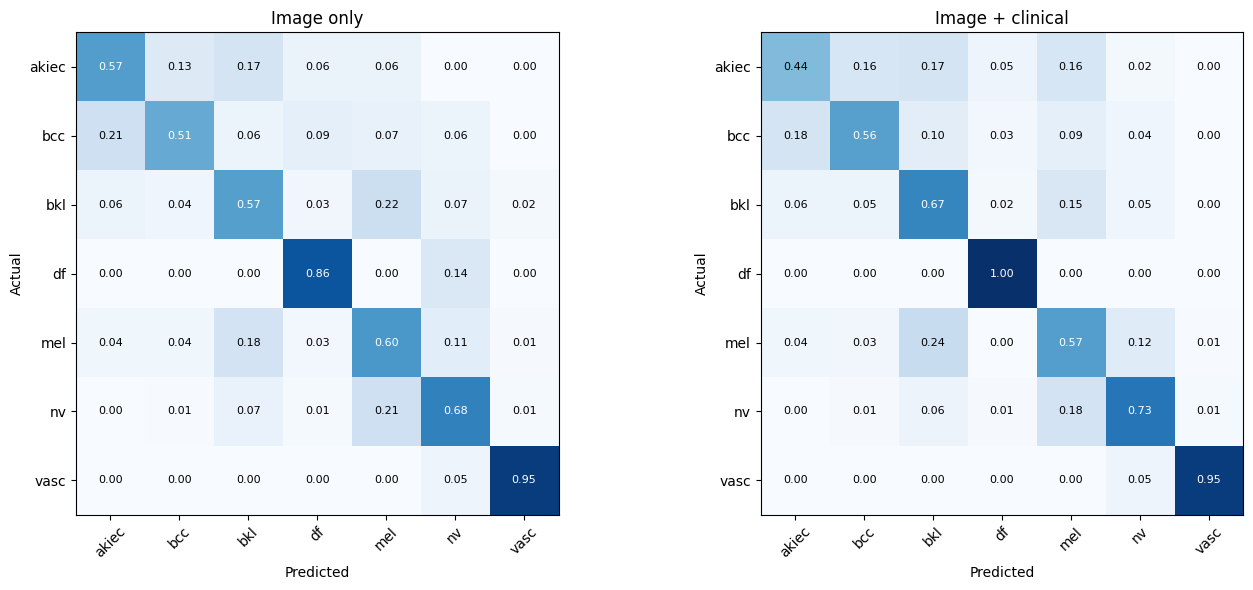

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, title in zip(axes, (pred_img, pred_mm), ("Image only", "Image + clinical")):
    cm = confusion_matrix(y_true, pred, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45)
    ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

## 10. What to write in your README and say in interviews

**Fill in from your own results above:** the numbers in the results table (macro recall, macro F1, melanoma recall) for both models, and how much the clinical data helped.

**Design decisions worth explaining (all true to this notebook):**
- Split by `lesion_id` to avoid leakage between train and test.
- Imputation, scaling and encoding fitted on the training set only.
- Class weights plus augmentation for the class imbalance; recall-focused evaluation because a missed cancer is the costly error.
- Two-phase transfer learning: train the new head first, then fine-tune the top of the backbone at a low learning rate.
- Compared image-only against multimodal, so the benefit of fusion is measured and not assumed.

**Honest limitations:** single public dataset, no external validation, dermatoscopic images only, a research prototype and not a medical device.

**Good extensions:** Grad-CAM heatmaps for explainability, probability calibration, and testing on another dataset such as ISIC.